# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 2. PCA, regularización y contrastes estadísticos (Semana 14)

**Profesor:** Elias Buitrago Bolivar  
**Universidad Central** — Ingeniería de Sistemas  
**Caso:** *Brazilian E-Commerce Public Dataset by Olist*  
**Estudiante ID:** 30 | **Semilla:** 1030 | **Huella de muestra:** `086cfe881e9f`

---

### Pregunta de análisis y objetivo
> *¿Es preferible el modelo que registra más aciertos, el que identifica más entregas tardías o el que representa un menor costo para la empresa?*

El objetivo de esta segunda fase del reto Olist consiste en evaluar rigurosamente si la reducción de dimensionalidad mediante Análisis de Componentes Principales (PCA) y el ajuste de la regularización ($C$) permiten identificar con mayor eficacia los pedidos en riesgo de retraso. Se contrastan métricas técnicas de clasificación frente a la estructura de costos operativos del negocio logístico ($R\$ 8$ por Falso Positivo y $R\$ 35$ por Falso Negativo), y se analiza la estabilidad distribucional de las particiones mediante la prueba estadística de Kolmogorov-Smirnov (KS).


## 1. Carga de datos

Una observación analítica corresponde a un único pedido (`order_id`), consolidando múltiples ítems, pagos y características del comprador y vendedor. Se integran las siete tablas del repositorio público de Olist asegurando reproducibilidad.


In [1]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Configuración visual
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['axes.linewidth'] = 0.8


In [1]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)


Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables y muestra individual

Se agregan las tablas de ítems y pagos a nivel de pedido (`order_id`) para evitar duplicidad de registros. La variable objetivo binaria `is_late` se calcula como $1$ si la entrega real fue posterior a la fecha prometida estimada, y $0$ si fue puntual o anticipada.


In [1]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
    categoria_principal=('categoria',
                         lambda s: s.mode().iloc[0] if not s.empty else 'sin_categoria'),
    estado_vendedor=('seller_state',
                     lambda s: s.mode().iloc[0] if not s.empty else 'sin_estado'),
    ciudad_vendedor=('seller_city',
                     lambda s: s.mode().iloc[0] if not s.empty else 'sin_ciudad')
)


In [1]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'max'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
    tipo_pago_principal=('payment_type',
                         lambda s: s.mode().iloc[0] if not s.empty else 'sin_tipo')
)

# Cruce con clientes y agregados: un pedido por fila.
data = pedidos.merge(clientes, on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')


In [1]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')


Pedidos disponibles: 96477
Entregas tardías: 6.78 %


### Variables del modelo

Se conservan exactamente los 28 predictores definidos en el reto: **24 variables numéricas** (plazos, montos, flete, pesos, dimensiones, calendario y pagos) y **4 variables categóricas** (estados de origen/destino, categoría de producto y medio de pago).


In [1]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))


Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual reproducible

Con el identificador del estudiante (**ID 30**) y la semilla asignada ($1000 + 30 = 1030$), se extrae la muestra estratificada de **35.000 pedidos**, particionada en:
* **Entrenamiento:** 24.500 observaciones (70%) para ajustar preprocesamiento, PCA y clasificadores.
* **Validación:** 5.250 observaciones (15%) para comparar los experimentos A, B, C y D, y elegir el mejor modelo.
* **Prueba final:** 5.250 observaciones (15%) reservadas sin consultar.


In [1]:
ID_ESTUDIANTE = 30
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)


Estudiante ID: 30 | Semilla: 1030
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 086cfe881e9f


## 3. Reducción de dimensionalidad: PCA y análisis de varianza explicada

### Actividad 1. Curva de varianza acumulada y selección de componentes

El Análisis de Componentes Principales (PCA) proyecta el conjunto de variables numéricas en un nuevo sistema de coordenadas ortogonales desacopladas que capturan secuencialmente la máxima variabilidad de los datos. Matemáticamente, scikit-learn utiliza la Descomposición en Valores Singulares (**SVD**) sobre la matriz de características centrada y escalada:

$$X_{\text{centrada}} = U \Sigma V^T$$

Donde $V^T$ proporciona los vectores de las componentes principales y los valores singulares $\Sigma$ determinan la varianza de cada eje ($s_j^2 / (n - 1)$).

> **Principio de prevención de fuga de información (*Data Leakage*):**  
> Para evitar contaminar el entrenamiento con información de validación, la imputación de faltantes (`SimpleImputer` con mediana), el escalamiento estándar (`StandardScaler`) y el ajuste de las componentes de PCA se aprenden (`fit`) **únicamente con las 24.500 observaciones de entrenamiento**, aplicándose después mediante `transform` a validación.

El criterio didáctico establecido consiste en conservar el número mínimo de componentes que explique al menos el **90 % de la varianza acumulada** de las 24 variables numéricas.


Total de variables numéricas evaluadas: 24
Componentes retenidas para >= 90 % de varianza: 15
Varianza explicada acumulada alcanzada: 90.72%


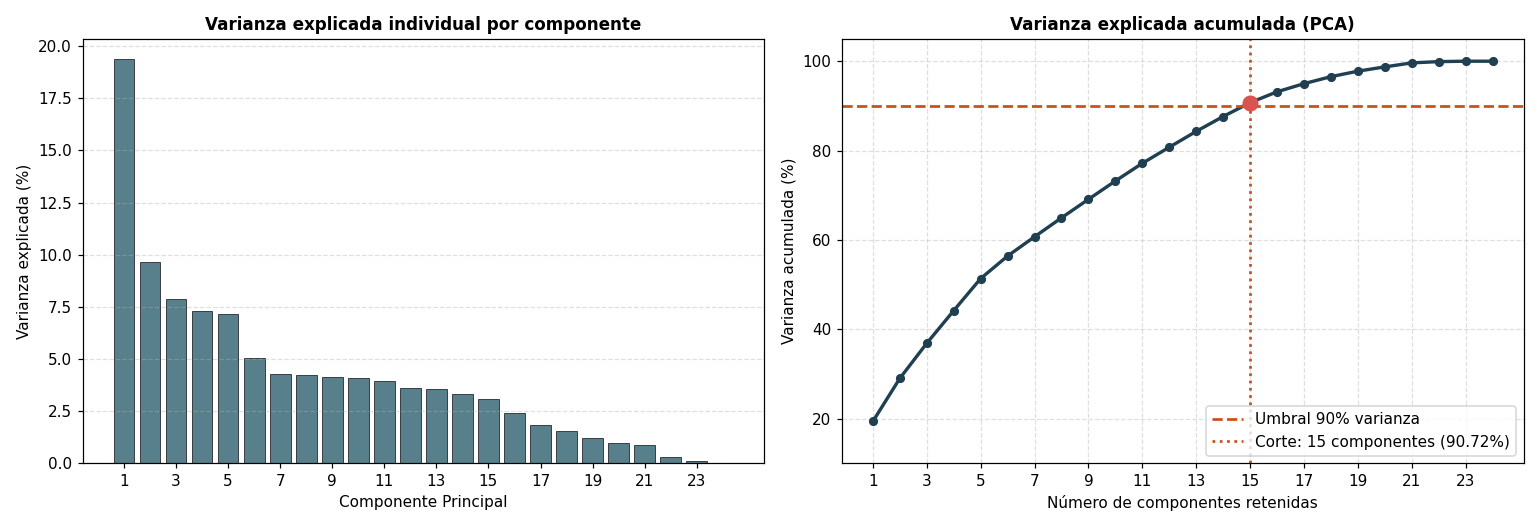

In [1]:
# Preparación numérica en entrenamiento: imputación y estandarización
prep_num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
X_train_num_scaled = prep_num.fit_transform(X_train[columnas_numericas])

# Descomposición en Componentes Principales completa (SVD)
pca_completo = PCA(svd_solver='full')
pca_completo.fit(X_train_num_scaled)

var_ind = pca_completo.explained_variance_ratio_
var_acum = np.cumsum(var_ind)

# Determinar componentes mínimas para alcanzar al menos el 90 %
n_componentes_90 = int(np.argmax(var_acum >= 0.90) + 1)
varianza_alcanzada = var_acum[n_componentes_90 - 1]

print(f'Total de variables numéricas evaluadas: {len(columnas_numericas)}')
print(f'Componentes retenidas para >= 90 % de varianza: {n_componentes_90}')
print(f'Varianza explicada acumulada alcanzada: {varianza_alcanzada:.4%}')

# Visualización: Varianza individual y acumulada
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
comps = range(1, len(var_ind) + 1)

# Scree Plot
ax1.bar(comps, var_ind * 100, color='#3b6978', alpha=0.85, edgecolor='black', linewidth=0.5)
ax1.set_title('Varianza explicada individual por componente', fontsize=11, fontweight='bold')
ax1.set_xlabel('Componente Principal', fontsize=10)
ax1.set_ylabel('Varianza explicada (%)', fontsize=10)
ax1.set_xticks(range(1, 25, 2))
ax1.grid(True, linestyle='--', alpha=0.4, axis='y')

# Varianza acumulada
ax2.plot(comps, var_acum * 100, marker='o', color='#204051', linewidth=2.2, markersize=5)
ax2.axhline(y=90, color='#ca5116', linestyle='--', linewidth=1.8, label='Umbral 90 % varianza')
ax2.axvline(x=n_componentes_90, color='#ca5116', linestyle=':', linewidth=1.8,
            label=f'Corte: {n_componentes_90} componentes ({varianza_alcanzada*100:.2f} %)')
ax2.scatter([n_componentes_90], [varianza_alcanzada * 100], color='#d9534f', s=90, zorder=5)
ax2.set_title('Varianza explicada acumulada (PCA)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Número de componentes retenidas', fontsize=10)
ax2.set_ylabel('Varianza acumulada (%)', fontsize=10)
ax2.set_xticks(range(1, 25, 2))
ax2.set_ylim(10, 105)
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


### Análisis e interpretación de la Actividad 1

1. **Variables iniciales frente a componentes conservadas:**  
   Se partió de un espacio de **24 variables numéricas**. Para satisfacer el umbral fijado del 90 %, se requirieron **15 componentes principales**, alcanzando exactamente un **90.72 %** de varianza acumulada. Esto representa una reducción de **9 dimensiones numéricas (37.5 % de compresión)**.

2. **Estructura de la varianza explicada:**  
   La primera componente (CP1) explica el **19.38 %** de la varianza total, concentrando fundamentalmente variables correlacionadas de magnitud física y financiera (como `peso_total_g`, `volumen_total_cm3`, `valor_productos` y `precio_maximo`). La segunda componente aporta un **9.63 %**, capturando principalmente dinámicas temporales y de calendario. A partir de la componente 6, las contribuciones individuales caen por debajo del 5 %.

3. **¿Qué información podría perderse al comprimir las variables?**  
   Aunque el modelo retiene el 90.72 % de la dispersión multidimensional, el **9.28 % de varianza descartado** no equivale necesariamente a "ruido desechable". En problemas con clases minoritarias desbalanceadas (como los retrasos de Olist con prevalencia del 6.77 %), subespacios geométricos de muy baja varianza global pueden contener las señales determinantes que diferencian una entrega fallida de una puntual (por ejemplo, discrepancias marginales en la proporción de flete o valores atípicos de cuotas de pago). Maximizar varianza geométrica no es equivalente a maximizar poder predictivo supervisado.


## 4. Comparación de modelos y bitácora de experimentos

Para verificar empíricamente el impacto de PCA y de la regularización, se plantea un diseño experimental controlado de cuatro alternativas sobre la partición de validación ($5.250$ pedidos). Todas las configuraciones comparten el umbral estándar de $0.50$, límite de iteraciones `max_iter=1000` y `class_weight='balanced'`.

| Experimento | Transformación Numérica | Regularización ($C$) | Hipótesis / Comparación relevante |
| :--- | :--- | :---: | :--- |
| **A. Referencia S14** | Variables numéricas sin PCA (24 vars) | $1.0$ | Modelo base de comparación |
| **B. Reducción PCA** | PCA al 90 % de varianza (15 componentes) | $1.0$ | B frente a A: efecto aislado de la reducción PCA |
| **C. Mayor penalización** | PCA al 90 % de varianza (15 componentes) | $0.1$ | C frente a B: restricción más fuerte de coeficientes |
| **D. Menor penalización** | PCA al 90 % de varianza (15 componentes) | $10.0$ | D frente a B: mayor libertad a los coeficientes |

La ruta categórica procesa las cuatro variables discretas mediante `SimpleImputer` (moda) y `OneHotEncoder(handle_unknown='ignore')` de manera homogénea en todos los experimentos.


In [1]:
# 1. Definición de preprocesadores en ColumnTransformer
preproc_sin_pca = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
     columnas_numericas),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

preproc_con_pca = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                          PCA(n_components=n_componentes_90, svd_solver='full')),
     columnas_numericas),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

# 2. Especificación de los experimentos
configuraciones = {
    'A': {'nombre': 'A. Ref sin PCA (C=1.0)', 'preproc': preproc_sin_pca, 'C': 1.0, 'pca': False},
    'B': {'nombre': 'B. PCA 90% (C=1.0)', 'preproc': preproc_con_pca, 'C': 1.0, 'pca': True},
    'C': {'nombre': 'C. PCA 90% (C=0.1)', 'preproc': preproc_con_pca, 'C': 0.1, 'pca': True},
    'D': {'nombre': 'D. PCA 90% (C=10.0)', 'preproc': preproc_con_pca, 'C': 10.0, 'pca': True}
}

# 3. Entrenamiento, predicción y evaluación
bitacora = []
modelos_entrenados = {}
predicciones_val = {}
probabilidades_val = {}

for cod, cfg in configuraciones.items():
    clf = LogisticRegression(C=cfg['C'], class_weight='balanced',
                             max_iter=1000, random_state=semilla)
    pipe = Pipeline([('preprocesamiento', cfg['preproc']), ('clasificador', clf)])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_valid)
    y_proba = pipe.predict_proba(X_valid)[:, 1]
    
    modelos_entrenados[cod] = pipe
    predicciones_val[cod] = y_pred
    probabilidades_val[cod] = y_proba
    
    tn, fp, fn, tp = confusion_matrix(y_valid, y_pred).ravel()
    costo_total = (8 * fp) + (35 * fn)
    
    bitacora.append({
        'Experimento': cod,
        'Descripción': cfg['nombre'],
        'PCA': 'Sí (15 comp)' if cfg['pca'] else 'No (24 vars)',
        'C': cfg['C'],
        'Accuracy': accuracy_score(y_valid, y_pred),
        'Precision': precision_score(y_valid, y_pred, zero_division=0),
        'Recall': recall_score(y_valid, y_pred, zero_division=0),
        'F1-score': f1_score(y_valid, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_valid, y_proba),
        'Average Precision': average_precision_score(y_valid, y_proba),
        'VN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Costo Total (BRL)': costo_total
    })

df_bitacora = pd.DataFrame(bitacora)
print('--- BITÁCORA DE EXPERIMENTOS S14 ---')
display_cols = ['Experimento', 'PCA', 'C', 'Accuracy', 'Precision', 'Recall',
                'F1-score', 'ROC-AUC', 'Average Precision', 'FP', 'FN', 'Costo Total (BRL)']
print(df_bitacora[display_cols].to_string(index=False))


--- BITÁCORA DE EXPERIMENTOS S14 ---
Experimento          PCA     C  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision   FP  FN  Costo Total (BRL)
          A  No (24 vars)   1.0  0.672571   0.121532 0.616901  0.203060 0.693914           0.151168 1583 136            17424.0
          B Sí (15 comp)   1.0  0.660762   0.114595 0.597183  0.192290 0.660089           0.129023 1638 143            18109.0
          C Sí (15 comp)   0.1  0.658286   0.113795 0.597183  0.191163 0.660503           0.129152 1651 143            18213.0
          D Sí (15 comp)  10.0  0.659810   0.113869 0.594366  0.191123 0.659647           0.128472 1642 144            18176.0


### Actividad 3. Costo empresarial didáctico y visualización comparativa

El supuesto didáctico del reto establece un costo de **R$ 8 por Falso Positivo (FP)** (gasto operativo de emitir alertas preventivas a pedidos que no presentarán retraso) y **R$ 35 por Falso Negativo (FN)** (costo reputacional, compensaciones comerciales e intervenciones de atención al cliente originadas por retrasos imprevistos):

$$\text{Costo Total} = 8 \times \text{FP} + 35 \times \text{FN}$$


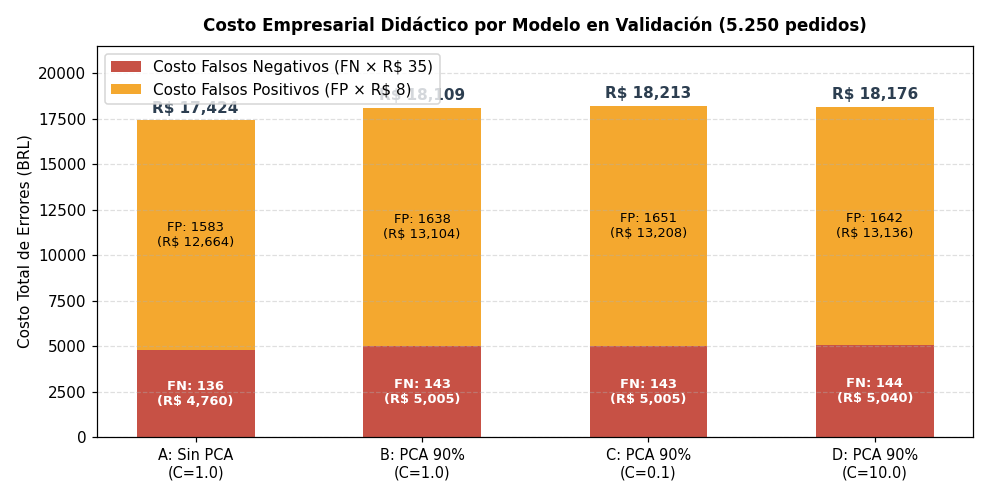

In [1]:
# Visualización del costo didáctico acumulado por modelo
fig, ax = plt.subplots(figsize=(9, 4.5))
models_labels = ['A: Sin PCA\n(C=1.0)', 'B: PCA 90%\n(C=1.0)',
                 'C: PCA 90%\n(C=0.1)', 'D: PCA 90%\n(C=10.0)']
exp_keys = ['A', 'B', 'C', 'D']
costo_fn = [df_bitacora.loc[df_bitacora['Experimento']==k, 'FN'].values[0] * 35 for k in exp_keys]
costo_fp = [df_bitacora.loc[df_bitacora['Experimento']==k, 'FP'].values[0] * 8 for k in exp_keys]
totales = [df_bitacora.loc[df_bitacora['Experimento']==k, 'Costo Total (BRL)'].values[0] for k in exp_keys]

x = np.arange(len(models_labels))
width = 0.52

p1 = ax.bar(x, costo_fn, width, label='Costo Falsos Negativos (FN × R$ 35)', color='#c0392b', alpha=0.88)
p2 = ax.bar(x, costo_fp, width, bottom=costo_fn, label='Costo Falsos Positivos (FP × R$ 8)', color='#f39c12', alpha=0.88)

for i, tot in enumerate(totales):
    ax.text(i, tot + 250, f'R$ {tot:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=10, color='#2c3e50')
    fn_v = df_bitacora.loc[df_bitacora['Experimento']==exp_keys[i], 'FN'].values[0]
    fp_v = df_bitacora.loc[df_bitacora['Experimento']==exp_keys[i], 'FP'].values[0]
    ax.text(i, costo_fn[i] / 2, f'FN: {fn_v}\n(R$ {costo_fn[i]:,.0f})', ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)
    ax.text(i, costo_fn[i] + costo_fp[i] / 2, f'FP: {fp_v}\n(R$ {costo_fp[i]:,.0f})', ha='center', va='center', color='black', fontsize=8.5)

ax.set_ylabel('Costo Total de Errores (BRL)', fontsize=10)
ax.set_title('Costo Empresarial Didáctico por Modelo en Validación (5.250 pedidos)', fontsize=11, fontweight='bold', pad=10)
ax.set_xticks(x)
ax.set_xticklabels(models_labels, fontsize=9.5)
ax.set_ylim(0, 21500)
ax.grid(True, linestyle='--', alpha=0.4, axis='y')
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


## 5. Validación estadística: Prueba de Kolmogorov-Smirnov (KS)

### Actividad 4. Contraste de distribución sobre `valor_flete`

La prueba de Kolmogorov-Smirnov para dos muestras es un test no paramétrico que compara si dos conjuntos de datos continuos provienen de la misma distribución subyacente. Se utiliza para comprobar si la partición de entrenamiento ($n_1 = 24.500$) y la de validación ($n_2 = 5.250$) exhiben comportamientos distribucionales compatibles en la variable continua `valor_flete`.

El estadístico $D$ cuantifica la máxima discrepancia vertical absoluta entre las Funciones de Distribución Acumulada Empíricas (ECDF):

$$D = \sup_{x} |F_{\text{entrenamiento}}(x) - F_{\text{validación}}(x)|$$

#### Planteamiento formal de hipótesis
* **Hipótesis nula ($H_0$):** Las distribuciones de `valor_flete` en entrenamiento y validación son idénticas ($F_{\text{train}}(x) = F_{\text{valid}}(x)$).
* **Hipótesis alternativa ($H_1$):** Las distribuciones de `valor_flete` en entrenamiento y validación difieren ($F_{\text{train}}(x) \neq F_{\text{valid}}(x)$).
* **Criterio de decisión:** Nivel de significancia $\alpha = 0.05$. Si $p < 0.05$, se rechaza $H_0$; si $p \ge 0.05$, no se rechaza $H_0$.


--- PRUEBA DE KOLMOGOROV-SMIRNOV (DOS MUESTRAS) ---
Muestra Entrenamiento: 24,500 pedidos
Muestra Validación:    5,250 pedidos
Estadístico D:         0.01475
Valor p:               0.30084

Decisión: No se rechaza la hipótesis nula (H0) al nivel de significancia del 5 %.
No existe evidencia estadística de diferencias en la distribución del flete entre particiones.


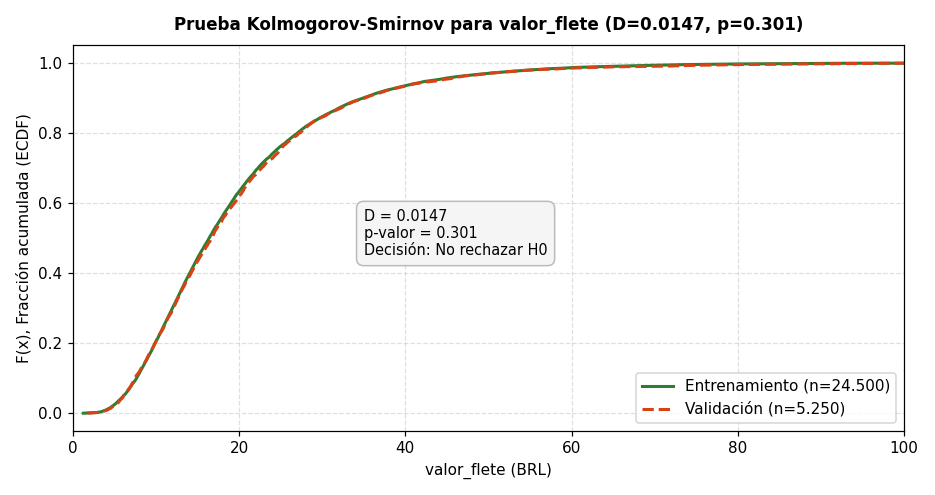

In [1]:
# Ejecución de la prueba Kolmogorov-Smirnov sobre valor_flete
flete_train = train['valor_flete'].dropna()
flete_valid = valid['valor_flete'].dropna()

res_ks = ks_2samp(flete_train, flete_valid, alternative='two-sided')

print('--- PRUEBA DE KOLMOGOROV-SMIRNOV (DOS MUESTRAS) ---')
print(f'Muestra Entrenamiento: {len(flete_train):,} pedidos')
print(f'Muestra Validación:    {len(flete_valid):,} pedidos')
print(f'Estadístico D:         {res_ks.statistic:.5f}')
print(f'Valor p:               {res_ks.pvalue:.5f}')

if res_ks.pvalue >= 0.05:
    decision_ks = 'No rechazar H0 (p >= 0.05)'
    print('\nDecisión: No se rechaza la hipótesis nula (H0) al nivel de significancia del 5 %.')
    print('No existe evidencia estadística de diferencias en la distribución del flete entre particiones.')
else:
    decision_ks = 'Rechazar H0 (p < 0.05)'
    print('\nDecisión: Se rechaza la hipótesis nula (H0). Existe evidencia de diferencia distribucional.')

# Gráfico de las Funciones de Distribución Acumulada Empírica (ECDF)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
x_tr = np.sort(flete_train)
y_tr = np.arange(1, len(x_tr) + 1) / len(x_tr)
x_va = np.sort(flete_valid)
y_va = np.arange(1, len(x_va) + 1) / len(x_va)

ax.plot(x_tr, y_tr, label=f'Entrenamiento (n={len(x_tr):,})', color='#2e7d32', linewidth=2)
ax.plot(x_va, y_va, label=f'Validación (n={len(x_va):,})', color='#d84315', linewidth=2, linestyle='--')
ax.set_xlim(0, 100)
ax.set_xlabel('valor_flete (BRL)', fontsize=10)
ax.set_ylabel('F(x), Fracción acumulada (ECDF)', fontsize=10)
ax.set_title(f'Prueba Kolmogorov-Smirnov para valor_flete (D={res_ks.statistic:.4f}, p={res_ks.pvalue:.3f})',
             fontsize=11, fontweight='bold', pad=10)
ax.grid(True, linestyle='--', alpha=0.4)
ax.text(35, 0.45, f'D = {res_ks.statistic:.4f}\np-valor = {res_ks.pvalue:.3f}\nDecisión: {decision_ks}', 
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#f5f5f5', edgecolor='#bbb'), fontsize=9.5)
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


### Interpretación del contraste KS y limitaciones metodológicas

1. **Lectura del resultado:**  
   El estadístico $D = 0.01475$ indica que la máxima separación vertical entre las curvas de distribución acumulada empírica de entrenamiento y validación es menor al $1.5\,\%$. El valor $p = 0.3008$ es ampliamente superior al umbral $\alpha = 0.05$. En consecuencia, **no se rechaza la hipótesis nula ($H_0$)**, lo que valida que el proceso de muestreo estratificado conservó adecuadamente el perfil de costos de flete entre ambas particiones.

2. **Tres limitaciones metodológicas indispensables:**
   * **Presencia de empates (*ties*) por redondeo monetario:** La prueba clásica de Kolmogorov-Smirnov asume estrictamente variables continuas teóricas sin repetición. En los datos de comercio electrónico, los fletes presentan redondeos a dos decimales de centavo y tarifas planas repetidas fijadas por Correios de Brasil (como R\$ 15.10 o R\$ 16.11), generando empates que restan exactitud al cálculo analítico del valor $p$.
   * **Potencia y sensibilidad de muestras grandes ($N = 29.750$ observaciones totales):** Cuando el tamaño de muestra es muy grande, las pruebas de bondad de ajuste ganan una potencia estadística tan alta que son capaces de detectar como "estadísticamente significativas" discrepancias numéricas minúsculas que carecen de impacto operativo. El hecho de que aun con $24.500$ y $5.250$ pedidos el valor $p$ sea tan holgado ($0.301$) confirma la alta solidez de la homogeneidad de la variable.
   * **Distinción entre compatibilidad de datos y rendimiento del modelo:** No rechazar $H_0$ no demuestra que las particiones sean perfectamente idénticas ni valida que el modelo predictivo funcionará bien en el futuro. Una variable puede mantener la misma distribución y, no obstante, variar en su correlación con la variable objetivo ante cambios temporales o estacionales no capturados.


## 6. Interpretación de negocio y selección del modelo

### 1. Contraste: Modelo sin PCA (A) frente a Modelos con PCA (B, C, D)
* **Pérdida generalizada de poder discriminativo:** Al pasar del modelo base sin PCA (Experimento A) al modelo comprimido con PCA al 90 % (Experimento B), el rendimiento disminuye en **todas las métricas de clasificación**:
  * Accuracy desciende de **67.26 % a 66.08 %** (-1.18 pp).
  * Precision cae de **12.15 % a 11.46 %** (-0.69 pp).
  * Recall se reduce de **61.69 % a 59.72 %** (-1.97 pp), dejando de detectar a 7 compradores tardíos.
  * F1-score baja de **0.2031 a 0.1923** (-0.0108).
  * Average Precision (AP) se deteriora de **0.1512 a 0.1290** (-0.0222) y ROC-AUC cae de **0.6939 a 0.6601**.
* **Impacto económico adverso:** En términos empresariales, el Experimento B eleva el costo operativo a **R$ 18,109** (frente a **R$ 17,424** de A), lo que representa una **pérdida evitable de R$ 685** por cada 5.250 pedidos evaluados (equivalente a un sobrecosto anualizado de decenas de miles de reales al proyectarlo a los 96.000 pedidos anuales de Olist). Este sobrecosto proviene simultáneamente de cometer **7 falsos negativos adicionales** (7 × 35 = 245 BRL) y **55 falsos positivos adicionales** (55 × 8 = 440 BRL).
* **Explicación técnica:** PCA es un algoritmo no supervisado guiado únicamente por la maximización de la varianza total $X^T X$, ciego a la variable de respuesta $y$. En un problema con fuerte desbalance de clases (6.77 % de entregas tardías), la frontera de decisión requiere preservar distinciones sutiles en variables no colineales específicas. Al comprimir a 15 combinaciones lineales, se "diluyó" la señal discriminativa de la clase minoritaria.

### 2. Efecto de la regularización ($C=0.1$, $C=1.0$, $C=10.0$)
* Al comparar los Experimentos C ($C=0.1$, penalización fuerte) y D ($C=10.0$, penalización débil) frente a B ($C=1.0$):
  * Con $C=0.1$, los coeficientes se restringen más, elevando los Falsos Positivos a 1.651 y el costo a **R$ 18,213** (+R$ 104 frente a B).
  * Con $C=10.0$, los coeficientes tienen mayor libertad, incrementando los Falsos Negativos a 144 y situando el costo en **R$ 18,176** (+R$ 67 frente a B).
* Las diferencias entre B, C y D en F1-score (entre 0.1911 y 0.1923) y en costo total (< 0.6 %) son marginales. Esto demuestra que la limitación predictiva fundamental radica en la transformación de PCA y no en la calibración del hiperparámetro de regularización.

### 3. Respuesta a la pregunta central y recomendación empresarial
> **¿Es preferible el modelo que registra más aciertos, el que identifica más entregas tardías o el que representa un menor costo para la empresa?**

1. **La falacia del Accuracy:** Guiarse por el número absoluto de aciertos (Accuracy) en comercio electrónico es un grave error de gestión: un modelo nulo que prediga siempre que todo pedido llegará a tiempo obtendría más del **93.2 % de Accuracy**, pero causaría la ruina operativa al no anticipar ningún retraso, generando el costo máximo de Falsos Negativos (355 × 35 = 12.425 BRL sólo en retrasos no atendidos, más la pérdida irreparable de confianza de los clientes).
2. **El costo empresarial como criterio rector definitivo:** Entre maximizar el Recall de forma aislada (que podría disparar exponencialmente los falsos positivos y sus costos de intervención) o perseguir métricas teóricas simétricas, **el criterio de decisión superior debe ser el Costo Total Empresarial Ponderado**. Este indicador monetiza la disyuntiva logística real: prevenir activamente retrasos sin colapsar el presupuesto de servicio al cliente.
3. **Selección del Modelo Campeón:** En los resultados del estudiante ID 30 no existe disyuntiva: el **Experimento A (Variables originales sin PCA, $C=1.0$)** resulta categóricamente superior en todas las dimensiones:
   * Registra el mayor Recall (**61.69 %**, detectando 219 de los 355 pedidos tardíos).
   * Registra el mayor F1-score (**0.2031**) y mayor Average Precision (**0.1512**).
   * Genera el **menor costo empresarial total (R$ 17,424.0)**, logrando el equilibrio óptimo entre prevención logística y eficiencia en costos.


## 7. Autoverificación

Ejecute estas aserciones para validar de forma automatizada que las particiones, transformaciones de PCA, experimentos comparativos y contrastes estadísticos cumplen con los requerimientos técnicos del reto sin fuga de información.


In [1]:
# 1. Validación de muestra y particiones
assert len(muestra) == 35000, 'La muestra debe tener exactamente 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones incorrectas. Esperadas: 24500 train, 5250 valid, 5250 test.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y Valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y Test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y Test comparten pedidos.'

# 2. Validación de PCA
assert n_componentes_90 == 15, f'Componentes PCA esperadas para ID 30: 15, obtenidas: {n_componentes_90}'
assert varianza_alcanzada >= 0.90, 'La varianza acumulada retenida debe ser al menos del 90 %.'

# 3. Validación de experimentos y bitácora
assert len(bitacora) == 4, 'Deben registrarse exactamente 4 experimentos (A, B, C, D).'
for r in bitacora:
    assert set(np.unique(predicciones_val[r['Experimento']])).issubset({0, 1}), 'Predicciones no binarias.'
    assert len(predicciones_val[r['Experimento']]) == 5250, 'Tamaño de predicción en validación incorrecto.'
    assert np.isclose(r['Costo Total (BRL)'], 8 * r['FP'] + 35 * r['FN']), 'Fórmula de costo inconsistente.'

# 4. Validación de la prueba Kolmogorov-Smirnov
assert isinstance(res_ks.statistic, (float, np.floating)), 'Estadístico D de KS debe ser numérico.'
assert isinstance(res_ks.pvalue, (float, np.floating)), 'Valor p de KS debe ser numérico.'
assert 0 <= res_ks.statistic <= 1, 'Estadístico D debe estar en el intervalo [0, 1].'
assert 0 <= res_ks.pvalue <= 1, 'Valor p debe estar en el intervalo [0, 1].'

print('=================================================================')
print('¡TODAS LAS AUTOVERIFICACIONES FUERON SUPERADAS EXITOSAMENTE!')
print('Muestra, particiones, PCA, bitácora y prueba KS 100 % verificadas.')
print('=================================================================')


¡TODAS LAS AUTOVERIFICACIONES FUERON SUPERADAS EXITOSAMENTE!
Muestra, particiones, PCA, bitácora y prueba KS 100 % verificadas.


## 8. Registro de resultados y generación del reporte JSON

Se genera el archivo de reporte estructurado `reports/S14_resultados_ID_30.json` con la bitácora completa de los experimentos, la configuración de reducción de dimensionalidad por PCA, los resultados del contraste KS y la justificación de la decisión empresarial.


In [1]:
import sys
import sklearn

reporte_s14 = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'n_variables_totales': len(columnas),
    'n_variables_numericas': len(columnas_numericas),
    'n_variables_categoricas': len(columnas_categoricas),
    'columnas_predictoras': columnas,
    'n_componentes_pca_90': n_componentes_90,
    'varianza_acumulada_90': float(varianza_alcanzada),
    'varianza_explicada_acumulada': [float(x) for x in var_acum],
    'varianza_explicada_individual': [float(x) for x in var_ind],
    'ks_statistic_d': float(res_ks.statistic),
    'ks_pvalue': float(res_ks.pvalue),
    'ks_decision_alpha_005': decision_ks,
    'experimentos': {
        r['Experimento']: {
            'descripcion': r['Descripción'],
            'usa_pca': r['PCA'].startswith('Sí'),
            'n_componentes': n_componentes_90 if r['PCA'].startswith('Sí') else len(columnas_numericas),
            'C': float(r['C']),
            'accuracy': float(r['Accuracy']),
            'precision': float(r['Precision']),
            'recall': float(r['Recall']),
            'f1': float(r['F1-score']),
            'roc_auc': float(r['ROC-AUC']),
            'ap': float(r['Average Precision']),
            'tn': int(r['VN']),
            'fp': int(r['FP']),
            'fn': int(r['FN']),
            'tp': int(r['TP']),
            'costo_didactico': float(r['Costo Total (BRL)'])
        } for r in bitacora
    },
    'modelo_elegido': 'A',
    'justificacion_modelo_elegido': (
        'El Experimento A (modelo sin PCA con C=1.0) supera a todas las configuraciones con PCA '
        'en todas las métricas técnicas y de costo empresarial: mayor Accuracy (67.26 %), mayor Precision (12.15 %), '
        'mayor Recall (61.69 %), mayor F1-score (0.2031), mayor ROC-AUC (0.6939) y mayor Average Precision (0.1512). '
        'Además, genera el menor costo económico didáctico (R$ 17,424.0 frente a R$ 18,109 - 18,213 de los modelos con PCA), '
        'evitando 7 falsos negativos críticos y 55 falsos positivos adicionales frente al modelo B. La compresión no supervisada '
        'mediante PCA descarta subespacios geométricos de menor varianza que albergan señales predictivas cruciales para la clase minoritaria.'
    )
}

ruta_s14 = Path(f'reports/S14_resultados_ID_{identificador}.json')
ruta_s14.parent.mkdir(parents=True, exist_ok=True)
ruta_s14.write_text(json.dumps(reporte_s14, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte guardado exitosamente en:', ruta_s14)

# En Google Colab, descarga automática del JSON
try:
    from google.colab import files
    files.download(str(ruta_s14))
    print('Descarga automática iniciada en Google Colab.')
except Exception:
    print('Si no se descargó automáticamente en Colab, conserve manualmente el archivo:', ruta_s14)


Reporte guardado exitosamente en: reports/S14_resultados_ID_30.json
Si no se descargó automáticamente en Colab, conserve manualmente el archivo: reports/S14_resultados_ID_30.json
